# Simulating `controlled_swap_trotter_test`

Master-equation simulation of the runtime, with loss, producing the runtime's four plots.

**No phase correction** -- every slope is zero, so the frame drift is assumed absent rather
than tracked. That makes every $W_{sym}$ step identical, which is what lets one step's
superoperator be raised to the $n$th power instead of solving 760 pulses per point.

The sideband coupling is $H = g\,(a\,\sigma^+ e^{i\phi} + a^\dagger \sigma^- e^{-i\phi})$. A
full swap is a $\pi$ rotation of the g1e0 two-level system, i.e. area $\pi/2$, so
$g = \pi / (2\,t_{swap})$ is fixed by the measured swap time, and the short pulse's area is
$\epsilon = g\,t_{short}$. The pulse's **rotation angle is $2\epsilon$**, not $\epsilon$:
a full swap is area $\pi/2$ AND a $\pi$ rotation. Dropping that factor makes
$\theta_{step}$ come out 4x small, so it is anchored below on a solve where one area-$\pi/2$
pulse really does give $P(\text{swapped}) = 1$.

In [26]:
import numpy as np                                     # arrays and math
import qutip as qt                                     # master-equation solver
import matplotlib                                      # colormaps
import matplotlib.pyplot as plt                        # plots

# ---- pulse times, as the config states them (ramp and flat, in seconds) -------------
ramp = 10e-9                                           # every one of these pulses ramps 10 ns
swap_flat = {1: 770.061627e-9, 2: 770.639e-9}          # Q1C1_swap, Q1C2_swap flat lengths
short_flat = {1: 100e-9, 2: 100e-9}                      # Q1C1_short, Q1C2_short flat lengths

# Two different times matter and they are not the same number:
#   effective time = flat + ramp/2  -- the first-order area weighting, what sets the rotation
#   wall time      = flat + ramp    -- how long the pulse actually occupies, what loss sees
swap_eff = {leg: swap_flat[leg] + ramp / 2 for leg in (1, 2)}      # area time of a full swap
short_eff = {leg: short_flat[leg] + ramp / 2 for leg in (1, 2)}    # area time of a short pulse
short_wall = {leg: short_flat[leg] + ramp for leg in (1, 2)}       # real duration, for loss

# ---- the coupling, derived from the swap times -------------------------------------
g = {leg: np.pi / (2 * swap_eff[leg]) for leg in (1, 2)}           # full swap = area pi/2
eps = {leg: g[leg] * short_eff[leg] for leg in (1, 2)}             # short-pulse area, rad
theta = 2 * eps[1] * eps[2]                            # per-step swap angle
n_star = (np.pi / 4) / theta                           # steps to a controlled SWAP

# ---- coherence times (assumptions -- edit these) -----------------------------------
t1_c1 = 900e-6                                          # C1 photon lifetime
t1_c2 = 130e-6                                          # C2 photon lifetime
t2_c1 = 700e-6                                         # C1 total dephasing time
t2_c2 = 250e-6                                         # C2 total dephasing time
t1_qubit = 200e-6                                       # qubit relaxation
t2_qubit = 350e-6                                       # qubit total dephasing time

# ---- what the cavities start in -----------------------------------------------------
# n_cav is levels per cavity: 2 is enough for one photon, 3 lets you prepare |2,0>. The whole
# operator set below is built from it, so raising it is the only change needed.
#
# cavity_prep is the two-cavity ket the shot starts in -- the simulation's equivalent of the
# runtime's cavity_prep_pulse_list. The qubit is prepared separately, on the equator.
n_cav = 9
cavity_prep = qt.tensor(qt.basis(n_cav, 8), qt.basis(n_cav, 0))    # |8,0>
prep_label = "|8,0>"                                   # titles only
# How many photons, summed across the two cavities, a shot must find to be KEPT by the
# post-selected panels. Match it to cavity_prep: 1 for |1,0>, 2 for |2,0>, and so on. Shots
# that miss it are the erasure fraction. Same meaning as the runtime's postselect_photons.
postselect_photons = 8

# ---- the sweep, matching the deployed run ------------------------------------------
steps = list(range(0, 100, 1))                          # trotter_steps: spans n* and 2n*
preps = ["+", "-"]                                     # control_states
read_phase = np.pi / 2                                 # closing pi/2 axis: pi/2 means sigma_y

# ---- residual phase-calibration error ----------------------------------------------
# The runtime applies  phase = base + own*N_own + other*N_other  to every pump pulse, and
# base + 4n(m1+m2) to the closing qubit pi/2. Setting these NONZERO is exactly the case where
# the phase calibration is WRONG by that much per sideband: the error then accumulates
# LINEARLY over the train, which is what a miscalibrated slope does.
# Zero means the calibration is assumed perfect. Set any of them by hand to see what a
# residual of that size costs -- these are the same six numbers the runtime takes.
own_slope = {1: 0.0, 2: 0.0}                           # a leg's pulses on its OWN transition
other_slope = {1: 0.0, 2: 0.0}                         # the other leg's pulses on it
qubit_slope = {1: 0.0, 2: 0.0}                         # the qubit frame, on the closing pi/2

## Operators

Space is $C_1 \otimes C_2 \otimes \text{qubit}$, two levels each -- one photon never makes
three. Leg A (q1C1) exchanges a $C_1$ photon for a qubit excitation, leg B (q1C2) a $C_2$ one.

In [27]:
i2 = qt.qeye(2)                                        # the QUBIT identity
ic = qt.qeye(n_cav)                                    # a CAVITY identity
a1 = qt.tensor(qt.destroy(n_cav), ic, i2)              # C1 lowering operator
a2 = qt.tensor(ic, qt.destroy(n_cav), i2)              # C2 lowering operator
sm = qt.tensor(ic, ic, qt.destroy(2))                  # qubit lowering operator (|g><e|)
n1_op = a1.dag() * a1                                  # C1 photon number
n2_op = a2.dag() * a2                                  # C2 photon number
pe_op = sm.dag() * sm                                  # qubit excited-state projector
mode = {1: a1, 2: a2}                                  # which cavity each leg couples to

# PURE dephasing rates: the total dephasing time minus the part relaxation already causes.
# The two operators are normalised differently, so the two formulas differ:
#   qubit,  L = sqrt(g/2) sigma_z   -> g/e coherence decays at g, so 1/T2 = 1/(2T1) + g
#   cavity, L = sqrt(g) a^dag a     -> the 0-1 coherence decays at g/2 (the rate goes as
#                                      (delta n)^2, and delta n = 1 here), so
#                                      1/T2 = 1/(2T1) + g/2
# Hence the factor 2 on the cavity lines. Clamped at 0: a T2 longer than 2*T1 is unphysical
# and would ask for a negative rate.
gamma_phi = max(1.0 / t2_qubit - 1.0 / (2 * t1_qubit), 0.0)          # qubit pure dephasing
gamma_c1 = max(2.0 / t2_c1 - 1.0 / t1_c1, 0.0)                       # C1 pure dephasing
gamma_c2 = max(2.0 / t2_c2 - 1.0 / t1_c2, 0.0)                       # C2 pure dephasing
c_ops = [np.sqrt(1.0 / t1_c1) * a1,                    # C1 photon decay
         np.sqrt(1.0 / t1_c2) * a2,                    # C2 photon decay
         np.sqrt(1.0 / t1_qubit) * sm,                 # qubit relaxation
         np.sqrt(gamma_phi / 2) * (2 * pe_op - qt.qeye([n_cav, n_cav, 2])),   # qubit dephasing
         np.sqrt(gamma_c1) * n1_op,                    # C1 dephasing (photon-number)
         np.sqrt(gamma_c2) * n2_op]                    # C2 dephasing (photon-number)

## Every pulse of the train

Every pulse's phase is the runtime's own expression,
$\phi = \text{base} + m_{own}N_{own} + m_{other}N_{other}$, with the six slopes set to a
residual up to $\pm 0.01$ rad per sideband -- i.e. the case where the phase calibration is
**wrong** by that much. The error then grows **linearly** across the train, which is what a bad
slope does and what a per-pulse scatter does not.

Because the phase now differs from step to step, the train is walked pulse by pulse and the
state snapshotted at each step count, rather than raising one step to the $n$th power.

One step is $W(-\epsilon)W(+\epsilon)$: eight pulses, legs strictly alternating B A B A, signs
$(+,+,-,-,-,-,+,+)$ -- built exactly as the runtime's `wsym_train` does. Four pulses of each
leg per step, which is where the $4n$ in the qubit read axis comes from.

In [28]:
train = []                                             # the LONGEST train, (leg, sign) in order
for _ in range(max(steps)):                            # one group of eight per W_sym step
    for e in (-1, +1):                                 # W(-eps) plays first, then W(+eps)
        train += [(2, -e), (1, -e), (2, +e), (1, +e)]  # B, A, B, A -- strictly alternating

base_phase = {1: np.pi / 2, 2: 0.0}                    # relative_pump_phase_rad on A, B at 0
played = {1: 0, 2: 0}                                  # pulses of each leg played so far
pulse_phase = []                                       # the phase of every pulse, in order
for leg, sign in train:                                # walk the train once
    other = 2 if leg == 1 else 1                       # the other leg
    pulse_phase.append(base_phase[leg]                 # the intended axis
                       + (np.pi if sign < 0 else 0.0)  # a -1 sign is just pi of phase
                       + own_slope[leg] * played[leg]           # drift from its own pulses
                       + other_slope[leg] * played[other])      # drift from the other leg's
    played[leg] += 1                                   # this pulse has now played
pulse_phase = np.array(pulse_phase)                    # array, for the frame plot later

# One entry per DISTINCT (leg, phase). With the slopes at zero every step of the train plays
# the same eight phases, so the whole 8n-pulse train collapses to four entries -- leg A and
# leg B, each at its two signs. Give any slope a nonzero value and the phases stop repeating
# and every pulse gets its own, which is what the old code paid unconditionally.
#
# HOW a pulse is applied depends on how big the space is, and the difference is not a tuning
# knob -- it is whether the notebook runs at all:
#
#   dense  -- exponentiate the Liouvillian once per distinct pulse and keep the matrix. The
#             sweep is then matrix-vector products, which is the fastest thing available, but
#             the matrix is (dim^2)^2 complex and that grows as n_cav^8.
#   sparse -- never form the exponential. exp(L t) is applied straight to the vectorised
#             density matrix by Krylov iteration on a SPARSE L (0.02% filled at n_cav = 9).
#
# qt.propagator always takes the dense route: it integrates a dim^2 x dim^2 IDENTITY, and its
# stiff solver keeps about 15 copies of that, so it needs 15*(dim^2)^2 complex numbers before
# doing any physics -- 25 MB at n_cav = 3, 1.5 GB at n_cav = 5, 165 GB at n_cav = 9. That last
# number is the MemoryError a big cavity truncation hits, and the switch below is what avoids
# it. The cutover is measured against the propagator's real appetite, not the bare matrix.
dim = n_cav * n_cav * 2                                # C1 (x) C2 (x) qubit
propagator_bytes = 15 * (dim ** 2) ** 2 * 16           # what qt.propagator will try to hold
dense_ok = propagator_bytes <= 1e9                     # a gigabyte, the cutover
prop_cache = {}                                        # key -> dense propagator (numpy array)
liou_cache = {}                                        # key -> sparse L * pulse duration


def pulse_key(leg, phase):
    return (leg, round(float(phase), 12))              # exact repeats hit, drifted ones do not


for (leg, _sign), phase in zip(train, pulse_phase):    # solve each distinct pulse once
    key = pulse_key(leg, phase)
    if key in prop_cache or key in liou_cache:
        continue
    # Scale H so the integrated area is g*t_eff while the solve runs for the full wall time,
    # so the rotation and the loss duration are both right despite the ramp.
    amp = g[leg] * short_eff[leg] / short_wall[leg]    # effective constant amplitude
    h = amp * (mode[leg] * sm.dag() * np.exp(1j * phase)
               + mode[leg].dag() * sm * np.exp(-1j * phase))    # the sideband Hamiltonian
    if dense_ok:
        prop_cache[key] = qt.propagator(h, short_wall[leg], c_ops).full()   # loss included
    else:
        liou_cache[key] = (qt.liouvillian(h, c_ops).to("CSR").data_as("csr_matrix")
                           * short_wall[leg])

step_ns = 8 * short_wall[1] * 1e9                      # one step's duration, ns (legs equal)
print(f"dim {dim}, superoperator {dim ** 2} x {dim ** 2}"
      f" ({propagator_bytes / 1e9:.2f} GB for a dense propagator)"
      f" -> {'dense propagators' if dense_ok else 'sparse expm_multiply'},"
      f" {len(prop_cache) + len(liou_cache)} distinct pulses")


dim 162, superoperator 26244 x 26244 (165.30 GB for a dense propagator) -> sparse expm_multiply, 4 distinct pulses


## Sweep and closing $\pi/2$

The closing rotation is a $\pi/2$ about an equatorial axis. With `read_phase = pi/2` that axis
is $\sigma_y$, which maps $|{+}x\rangle \to |e\rangle$ and $|{-}x\rangle \to |g\rangle$ -- so at
$n=0$ prep $+$ reads $P(e)=1$, as the real run does.

After the rotation the qubit and both photon numbers are all diagonal in the same basis, so
the joint measurement is just the diagonal of $\rho$, indexed by $(n_1, n_2, q)$ -- which is
taken **exactly**. Nothing is sampled, so the curves carry no shot noise and no error bars:
they are what a run with infinitely many iterations would report.

In [29]:
# Exact, not sampled. After the closing pi/2 the qubit and both photon numbers are diagonal in
# the same basis, so the joint distribution P(n1, n2, q) IS the diagonal of rho -- every
# observable below is a weighted sum over it. There are no shots and therefore no shot noise
# and no error bars: these are the values a run with infinitely many iterations would report.
p_excited = np.zeros((len(preps), len(steps)))                    # P(qubit = e)
mean_photons = np.zeros((len(preps), len(steps), 2))              # <n1>, <n2>
heralded = np.zeros((len(preps), len(steps), 2, 2))               # [prep, step, qubit, line]
herald_weight = np.zeros((len(preps), len(steps), 2))             # P(qubit outcome)

# ---- the same quantities again, conditioned on finding postselect_photons ------------
# An outcome that lost a photon still enters the plain averages above as a zero and pulls the
# branch mean down, and loss grows with the train. Conditioning on the full photon number
# removes that: within that subspace <n1> + <n2> = postselect_photons, so what is left is the
# herald alone.
kept_fraction = np.zeros((len(preps), len(steps)))                # weight that survives
ps_p_excited = np.zeros((len(preps), len(steps)))                 # P(e) among kept
ps_mean_photons = np.zeros((len(preps), len(steps), 2))           # <n1>, <n2> among kept
ps_heralded = np.zeros((len(preps), len(steps), 2, 2))            # herald among kept
# P(n1 = j) among the kept shots, j = 0 .. postselect_photons. Post-selection pins n1 + n2 to
# that number, so n1 alone carries the whole partition. Kept once with the qubit IGNORED and
# once per qubit outcome -- theory says those coincide, because photon transfer out of a Fock
# state goes as sin^2, which is even in the angle the qubit controls.
levels = postselect_photons + 1
ps_c1_dist = np.full((len(preps), len(steps), levels), np.nan)
ps_c1_dist_by_qubit = np.full((2, len(preps), len(steps), levels), np.nan)

grid_n1 = np.arange(n_cav)[:, None] * np.ones((1, n_cav))         # n1 at each (n1, n2)
grid_n2 = np.ones((n_cav, 1)) * np.arange(n_cav)[None, :]         # n2 at each (n1, n2)
keep_mask = (grid_n1 + grid_n2) == postselect_photons             # the post-selection cut


def split(table):
    """(n1, n2) table -> (weight, <n1>, <n2>), with a guard on an empty branch."""
    w = table.sum()
    if w <= 0:
        return 0.0, np.nan, np.nan
    return w, (table * grid_n1).sum() / w, (table * grid_n2).sum() / w


# The walk is plain numpy. A Qobj carries enough per-operation overhead that the wrapped
# matrix-vector products cost more than the matrix exponentials that built them. QuTiP
# vectorises by COLUMN stacking (order="F"), which is what lets a density matrix be flattened
# and rebuilt here by hand.
#
# With the six slopes at zero every W_sym step plays the same eight phases, so on the dense
# path the eight pulse superoperators compose ONCE into a single step and the sweep advances a
# step at a time instead of a pulse at a time. Give any slope a nonzero value and the phases
# stop repeating and this falls back to walking every pulse, which is what the old code always
# did. The sparse path has no matrix to compose, so it always walks pulse by pulse.
from scipy.sparse.linalg import expm_multiply                      # only used on the big path

keys = [pulse_key(leg, ph) for (leg, _sign), ph in zip(train, pulse_phase)]
uniform = dense_ok and len(pulse_phase) % 8 == 0 and np.array_equal(
    pulse_phase.reshape(-1, 8), np.tile(pulse_phase[:8], (len(pulse_phase) // 8, 1)))
if uniform:
    step_super = np.linalg.multi_dot([prop_cache[k] for k in keys[7::-1]])  # last acts last
print(f"{len(keys)} pulses, "
      + ("one composed step, reused" if uniform else
         "dense, pulse by pulse" if dense_ok else "sparse, pulse by pulse"))

for pi_, prep in enumerate(preps):                     # the two antipodal preparations
    sgn = 1.0 if prep == "+" else -1.0                 # +X or -X on the qubit
    qubit0 = (qt.basis(2, 0) + sgn * qt.basis(2, 1)).unit()       # (|g> +- |e>)/sqrt2
    rho0 = qt.ket2dm(qt.tensor(cavity_prep, qubit0))   # the prepared cavities, qubit on +-X
    vec = rho0.full().flatten(order="F")               # flatten, so the superoperator applies

    snap = {0: vec}                                    # the state after each whole step
    if uniform:                                        # every step is the same map
        for n in range(1, max(steps) + 1):
            vec = step_super @ vec
            snap[n] = vec
    else:                                              # walk every pulse
        for i, key in enumerate(keys):
            vec = (prop_cache[key] @ vec if dense_ok
                   else expm_multiply(liou_cache[key], vec))
            if (i + 1) % 8 == 0:                       # a whole W_sym step just finished
                snap[(i + 1) // 8] = vec

    for ni, n in enumerate(steps):                     # every Trotter step count in the sweep
        rho = snap[n].reshape((dim, dim), order="F")   # back to a density matrix
        # The closing pi/2's axis carries the qubit frame the train accumulated: 4n pulses of
        # each leg, so 4n(m1+m2). Rebuilt per n because it grows with the step count.
        phi = read_phase + 4 * n * (qubit_slope[1] + qubit_slope[2])
        axis = np.cos(phi) * qt.sigmax() + np.sin(phi) * qt.sigmay()   # equatorial axis
        u_read = qt.tensor(ic, ic, (-1j * (np.pi / 4) * axis).expm()).full()
        rho = u_read @ rho @ u_read.conj().T           # apply the closing pi/2

        d = np.real(np.diag(rho))                      # joint P(n1, n2, q) -- all commute
        d = np.clip(d, 0, None)                        # kill tiny negative solver residue
        P = (d / d.sum()).reshape(n_cav, n_cav, 2)     # renormalise, then index by (n1, n2, q)

        _, mean_photons[pi_, ni, 0], mean_photons[pi_, ni, 1] = split(P.sum(2))
        p_excited[pi_, ni] = P[:, :, 1].sum()          # the qubit observable
        for q in (0, 1):                               # herald on each qubit outcome
            w, m1, m2 = split(P[:, :, q])
            herald_weight[pi_, ni, q] = w              # how much weight the branch carries
            heralded[pi_, ni, q] = [m1, m2]

        # ---- the post-selected subspace ------------------------------------------------
        kept = P * keep_mask[:, :, None]               # only the full-photon-number outcomes
        kept_fraction[pi_, ni] = kept.sum()
        if kept_fraction[pi_, ni] > 0:                 # P(n1 = j) across the kept subspace
            for j in range(levels):
                k = postselect_photons - j             # the n2 that pairs with n1 = j
                if 0 <= j < n_cav and 0 <= k < n_cav:
                    ps_c1_dist[pi_, ni, j] = kept[j, k].sum() / kept_fraction[pi_, ni]
                    for q in (0, 1):
                        w = kept[:, :, q].sum()
                        ps_c1_dist_by_qubit[q, pi_, ni, j] = (kept[j, k, q] / w
                                                              if w > 0 else np.nan)
                else:                                  # outside the truncation: no weight
                    ps_c1_dist[pi_, ni, j] = 0.0
                    ps_c1_dist_by_qubit[:, pi_, ni, j] = 0.0
        if kept_fraction[pi_, ni] > 0:
            norm = kept / kept_fraction[pi_, ni]       # renormalised onto the kept subspace
            _, ps_mean_photons[pi_, ni, 0], ps_mean_photons[pi_, ni, 1] = split(norm.sum(2))
            ps_p_excited[pi_, ni] = norm[:, :, 1].sum()
            for q in (0, 1):
                _, m1, m2 = split(norm[:, :, q])
                ps_heralded[pi_, ni, q] = [m1, m2]
        else:
            ps_mean_photons[pi_, ni] = np.nan
            ps_p_excited[pi_, ni] = np.nan
            ps_heralded[pi_, ni] = np.nan

total_photons = mean_photons.sum(2)                     # the photon budget, <n1> + <n2>
erased = 1.0 - kept_fraction                            # what the post-selection throws away
x = np.array(steps, float)                              # the sweep axis

# ---- the LOSSLESS reference, built by running the train rather than from the closed form ----
# Section 7 of CSWAP_TROTTER_SCALING.md derives the binomial for a LINEAR beamsplitter,
# a^dag b + a b^dag. The g1e0 sidebands only realise that in the ONE-excitation sector: what
# they drive is |g,n> <-> |e,n-1>, whose matrix element carries the sqrt(n) of the cavity
# ladder. With N photons loaded the synthesised interaction is NOT the beamsplitter, and both
# the rate and the shape drift -- at N = 8 the train needs n* = 12.28 where the closed form
# says 8.72, and its distribution is narrower. So the reference runs the train.
#
# The train conserves M = n1 + n2 + q exactly and this reference is lossless, so it lives in
# the M = N sector: 2N+1 states instead of (N+2)^2*2, which is why it costs milliseconds.
from scipy.linalg import expm as _expm

N_ref = postselect_photons
_basis = [(pp, N_ref - pp - ss, ss) for ss in (0, 1) for pp in range(N_ref - ss + 1)]
_index = {st: i for i, st in enumerate(_basis)}
_dim = len(_basis)
_step = np.eye(_dim, dtype=complex)
for _leg, _sgn in [(2, -e) for e in (-1,)] and [t for e in (-1, 1)
                   for t in ((2, -e), (1, -e), (2, e), (1, e))]:
    _ph = base_phase[_leg] + (np.pi if _sgn < 0 else 0.0)
    _h = np.zeros((_dim, _dim), dtype=complex)
    for (_p, _q, _s), _col in _index.items():
        _occ = _p if _leg == 1 else _q
        if _s == 0 and _occ > 0:             # mode * sigma^+ : the sqrt(n) lives here
            _out = (_p - 1, _q, 1) if _leg == 1 else (_p, _q - 1, 1)
            _h[_index[_out], _col] += eps[_leg] * np.sqrt(_occ) * np.exp(1j * _ph)
        if _s == 1:                          # mode^dag * sigma^-
            _out = (_p + 1, _q, 0) if _leg == 1 else (_p, _q + 1, 0)
            if _out in _index:
                _h[_index[_out], _col] += eps[_leg] * np.sqrt(_occ + 1) * np.exp(-1j * _ph)
    _step = _expm(-1j * _h) @ _step          # a pulse of AREA eps rotates by 2*eps

_vec = np.zeros(_dim, dtype=complex); _vec[_index[(N_ref, 0, 0)]] = 1.0
# post-selected means the CAVITIES held N photons, i.e. the qubit is down: q = 0
_shell = np.array([_index[(j, N_ref - j, 0)] for j in range(N_ref + 1)])
train_ref = np.zeros((int(max(steps)) + 1, N_ref + 1))
for _n in range(train_ref.shape[0]):
    _w = np.abs(_vec[_shell]) ** 2
    train_ref[_n] = _w / _w.sum() if _w.sum() > 0 else np.nan
    _vec = _step @ _vec
train_ref_x = np.arange(train_ref.shape[0], dtype=float)
print(f"train reference: N={N_ref}, {_dim}-state sector, "
      f"crosses <n1>=<n2> near n="
      f"{train_ref_x[np.argmin(np.abs((train_ref*np.arange(N_ref+1)).sum(1) - N_ref/2))]:.0f}")


792 pulses, sparse, pulse by pulse
train reference: N=8, 17-state sector, crosses <n1>=<n2> near n=12


## 1 herald, prep +

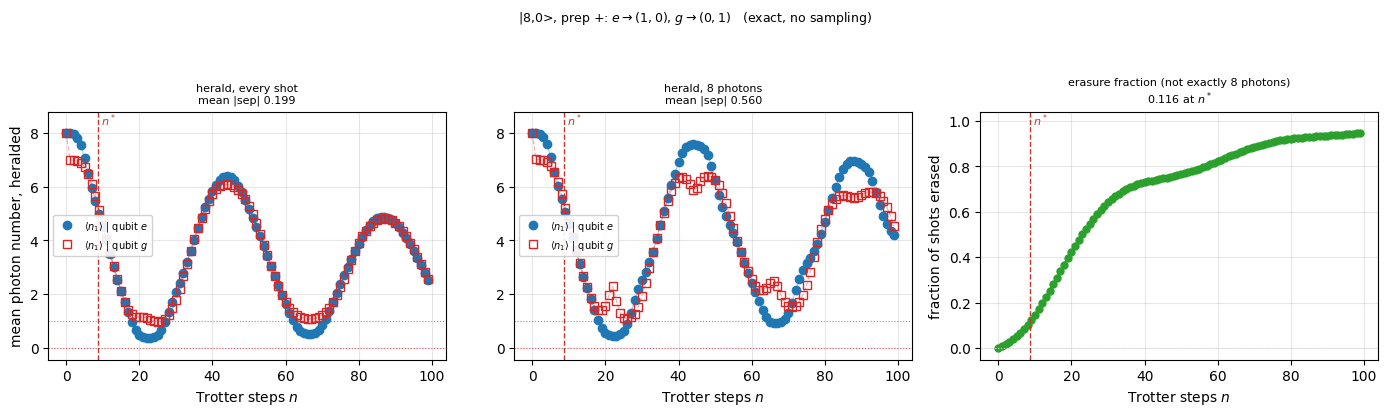

In [30]:
# One page per preparation, the same three panels the runtime draws: the herald over every
# shot, the herald over the post-selected shots, and the fraction erased. PREP is the only
# thing that differs between this page and the next.
ps_tag = "one photon" if postselect_photons == 1 else f"{postselect_photons} photons"
er_tag = (f"not exactly {postselect_photons} photon"
          f"{'s' if postselect_photons != 1 else ''}")
PREP = "+"
panel = preps.index(PREP)
n1_given_e = 1.0 if PREP == "+" else 0.0               # the pairing reverses with the prep

# y limits from the data, with a little headroom -- a multi-photon prep puts <n1>
# above 1, so a fixed ceiling would clip it.
top = 1.10 * max(float(np.nanmax(heralded[panel, :, :, 0])),
                 float(np.nanmax(ps_heralded[panel, :, :, 0])))
bot = -0.05 * top

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
for column, (values, tag) in enumerate((
        (heralded, "every shot"),
        (ps_heralded, ps_tag))):
    ax = axs[column]
    for q, name, colour, fill in ((1, "e", "C0", True), (0, "g", "C3", False)):
        y = values[panel, :, q, 0]                      # <n1> given that qubit outcome
        ax.plot(x, y, "-" if fill else "--", color=colour, lw=0.9, alpha=0.35)
        ax.plot(x, y, "o" if fill else "s", color=colour, markersize=6,
                markerfacecolor=colour if fill else "none",
                    label=r"$\langle n_1\rangle$ | qubit $" + name + "$")
    ax.axhline(n1_given_e, color="C0", ls=":", lw=0.8, alpha=0.7)        # where e should sit
    ax.axhline(1.0 - n1_given_e, color="C3", ls=":", lw=0.8, alpha=0.7)  # and where g should
    ax.set_xlabel("Trotter steps $n$")
    ax.set_ylim(bot, top)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc="center left", framealpha=0.9)
    ax.axvline(n_star, color="#c0392b", ls="--", lw=1.0)                 # n*, labelled
    ax.text(n_star, top, " $n^*$", color="#c0392b", fontsize=8, va="top")
    gap = float(np.mean(np.abs(values[panel, :, 1, 0] - values[panel, :, 0, 0])))
    ax.set_title(f"herald, {tag}\nmean |sep| {gap:.3f}", fontsize=8)
axs[0].set_ylabel("mean photon number, heralded")

er_top = 1.10 * max(float(np.nanmax(erased[panel])), 1e-9)   # the erasure axis
ax = axs[2]                                             # panel 3: what the post-selection cut
ax.plot(x, erased[panel], "-o", color="C2", markersize=5)
ax.axhline(0.0, color="0.85", lw=0.8, ls=":")
ax.axvline(n_star, color="#c0392b", ls="--", lw=1.0)
ax.text(n_star, er_top, " $n^*$", color="#c0392b", fontsize=8, va="top")
ax.set_xlabel("Trotter steps $n$")
ax.set_ylabel("fraction of shots erased")
ax.set_ylim(-0.05 * er_top, er_top)
ax.grid(True, alpha=0.3)
ax.set_title(f"erasure fraction ({er_tag})\n"
             f"{float(np.interp(n_star, x, erased[panel])):.3f} at $n^*$", fontsize=8)

herald = r"$e\to(1,0)$, $g\to(0,1)$" if PREP == "+" else r"$e\to(0,1)$, $g\to(1,0)$"
fig.suptitle(f"{prep_label}, prep ${PREP}$: {herald}   "
             f"(exact, no sampling)", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))

## 2 herald, prep -

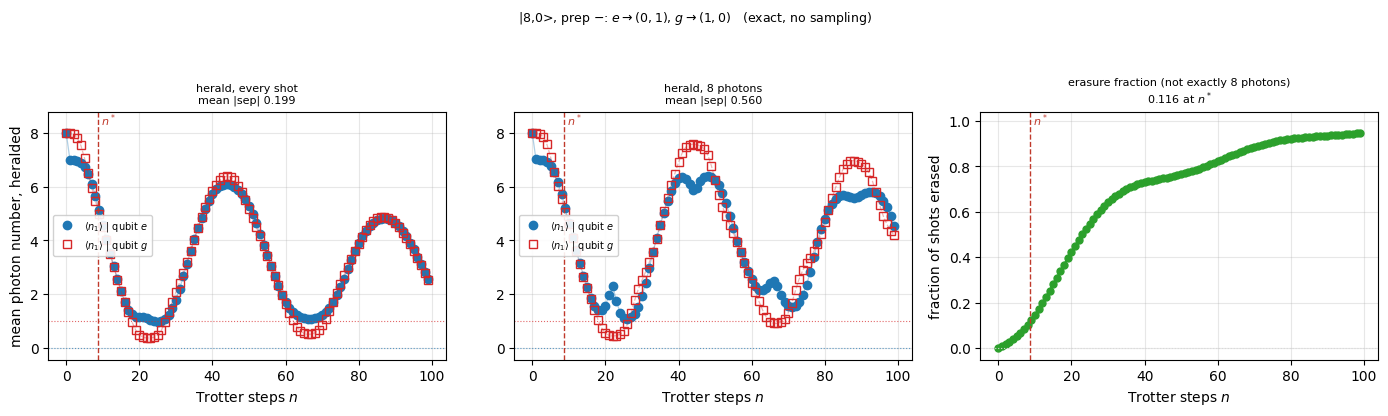

In [31]:
# One page per preparation, the same three panels the runtime draws: the herald over every
# shot, the herald over the post-selected shots, and the fraction erased. PREP is the only
# thing that differs between this page and the next.
ps_tag = "one photon" if postselect_photons == 1 else f"{postselect_photons} photons"
er_tag = (f"not exactly {postselect_photons} photon"
          f"{'s' if postselect_photons != 1 else ''}")
PREP = "-"
panel = preps.index(PREP)
n1_given_e = 1.0 if PREP == "+" else 0.0               # the pairing reverses with the prep

# y limits from the data, with a little headroom -- a multi-photon prep puts <n1>
# above 1, so a fixed ceiling would clip it.
top = 1.10 * max(float(np.nanmax(heralded[panel, :, :, 0])),
                 float(np.nanmax(ps_heralded[panel, :, :, 0])))
bot = -0.05 * top

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
for column, (values, tag) in enumerate((
        (heralded, "every shot"),
        (ps_heralded, ps_tag))):
    ax = axs[column]
    for q, name, colour, fill in ((1, "e", "C0", True), (0, "g", "C3", False)):
        y = values[panel, :, q, 0]                      # <n1> given that qubit outcome
        ax.plot(x, y, "-" if fill else "--", color=colour, lw=0.9, alpha=0.35)
        ax.plot(x, y, "o" if fill else "s", color=colour, markersize=6,
                markerfacecolor=colour if fill else "none",
                    label=r"$\langle n_1\rangle$ | qubit $" + name + "$")
    ax.axhline(n1_given_e, color="C0", ls=":", lw=0.8, alpha=0.7)        # where e should sit
    ax.axhline(1.0 - n1_given_e, color="C3", ls=":", lw=0.8, alpha=0.7)  # and where g should
    ax.set_xlabel("Trotter steps $n$")
    ax.set_ylim(bot, top)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc="center left", framealpha=0.9)
    ax.axvline(n_star, color="#c0392b", ls="--", lw=1.0)                 # n*, labelled
    ax.text(n_star, top, " $n^*$", color="#c0392b", fontsize=8, va="top")
    gap = float(np.mean(np.abs(values[panel, :, 1, 0] - values[panel, :, 0, 0])))
    ax.set_title(f"herald, {tag}\nmean |sep| {gap:.3f}", fontsize=8)
axs[0].set_ylabel("mean photon number, heralded")

er_top = 1.10 * max(float(np.nanmax(erased[panel])), 1e-9)   # the erasure axis
ax = axs[2]                                             # panel 3: what the post-selection cut
ax.plot(x, erased[panel], "-o", color="C2", markersize=5)
ax.axhline(0.0, color="0.85", lw=0.8, ls=":")
ax.axvline(n_star, color="#c0392b", ls="--", lw=1.0)
ax.text(n_star, er_top, " $n^*$", color="#c0392b", fontsize=8, va="top")
ax.set_xlabel("Trotter steps $n$")
ax.set_ylabel("fraction of shots erased")
ax.set_ylim(-0.05 * er_top, er_top)
ax.grid(True, alpha=0.3)
ax.set_title(f"erasure fraction ({er_tag})\n"
             f"{float(np.interp(n_star, x, erased[panel])):.3f} at $n^*$", fontsize=8)

herald = r"$e\to(1,0)$, $g\to(0,1)$" if PREP == "+" else r"$e\to(0,1)$, $g\to(1,0)$"
fig.suptitle(f"{prep_label}, prep ${PREP}$: {herald}   "
             f"(exact, no sampling)", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))

## 3 oscillation, both preps

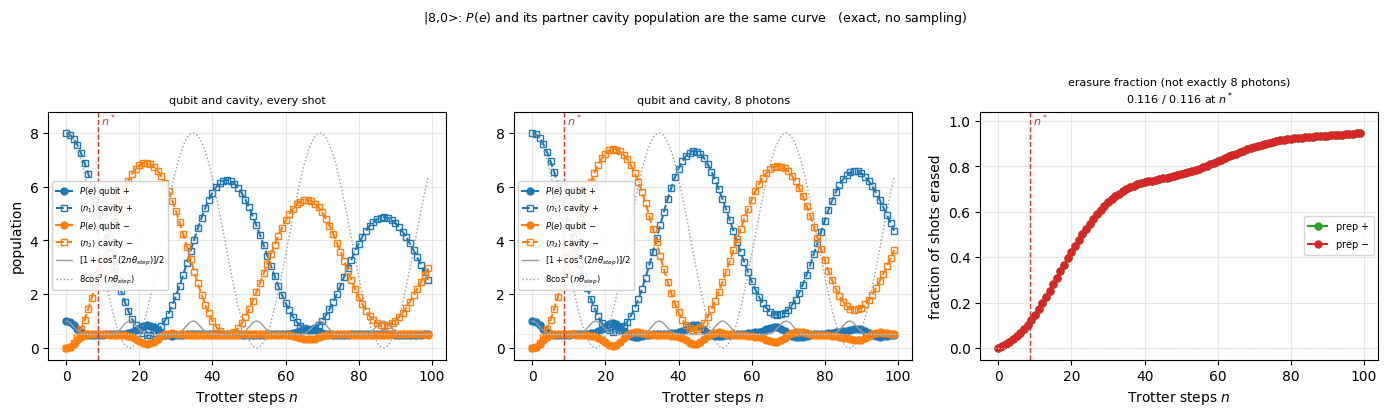

In [32]:
# Both preparations overlaid, the same three panels the runtime draws. P(e) and its PARTNER
# cavity population are the same curve: <n1> partners "+", <n2> partners "-", never crossed.
#
# The lossless reference depends on how many photons were prepared. For |N,0> the closed
# forms of CSWAP_TROTTER_SCALING.md section 7 are
#     P(e)   = [1 + cos^N(2 n theta)] / 2          -- NOT cos(2 N n theta): the qubit tracks
#     <n1>   = N cos^2(n theta)                       the PARITY of transferred photons, so
#                                                     the fringe LOSES contrast as N grows.
# Both collapse to cos^2(n theta) at N = 1, which is the single-photon case.
n_prep = float(qt.expect(qt.tensor(qt.destroy(n_cav).dag() * qt.destroy(n_cav), ic),
                         cavity_prep))                 # photons the prep put in C1
# y limits from the data, with headroom.
# max over each array separately -- they have different shapes, so one nanmax over a
# list of them is ragged. The reference is a floor so it stays fully visible.
ps_tag = "one photon" if postselect_photons == 1 else f"{postselect_photons} photons"
er_tag = (f"not exactly {postselect_photons} photon"
          f"{'s' if postselect_photons != 1 else ''}")
top = 1.10 * max(1.0, n_prep, *[float(np.nanmax(v)) for v in
                                (p_excited, ps_p_excited, mean_photons, ps_mean_photons)])
bot = -0.05 * top

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
for column, (pe, cav, tag) in enumerate((
        (p_excited, mean_photons, "every shot"),
        (ps_p_excited, ps_mean_photons, ps_tag))):
    ax = axs[column]
    for c, prep in enumerate(preps):
        line = 0 if prep == "+" else 1                  # which cavity partners this prep
        name = "n_1" if line == 0 else "n_2"
        ax.plot(x, pe[c], "-o", color=f"C{c}", markersize=5,
                label=f"$P(e)$ qubit ${prep}$")
        ax.plot(x, cav[c, :, line], "--s", color=f"C{c}", markersize=4,
                markerfacecolor="none", label=f"$\\langle {name} \\rangle$ cavity ${prep}$")
    fine = np.linspace(0, max(steps), 200)              # the lossless expectation
    N = int(round(n_prep))
    ax.plot(fine, (1 + np.cos(2 * fine * theta) ** N) / 2, "-", color="0.6", lw=1.0,
            label=(r"$\cos^2(n\theta_{step})$" if N == 1 else
                   rf"$[1+\cos^{{{N}}}(2n\theta_{{step}})]/2$"))
    if N != 1:                                          # the cavity's own reference splits off
        ax.plot(fine, N * np.cos(fine * theta) ** 2, ":", color="0.6", lw=1.0,
                label=rf"${N}\cos^2(n\theta_{{step}})$")
    ax.axhline(0.5, color="0.85", lw=0.8, ls=":")
    ax.set_xlabel("Trotter steps $n$")
    ax.set_ylim(bot, top)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=6, loc="center left", framealpha=0.9)
    ax.axvline(n_star, color="#c0392b", ls="--", lw=1.0)
    ax.text(n_star, top, " $n^*$", color="#c0392b", fontsize=8, va="top")
    ax.set_title(f"qubit and cavity, {tag}", fontsize=8)
axs[0].set_ylabel("population")

er_top = 1.10 * max(float(np.nanmax(erased)), 1e-9)   # the erasure axis
ax = axs[2]                                             # erasure, both preps on one panel
for c, prep in enumerate(preps):
    ax.plot(x, erased[c], "-o", color=f"C{2 + c}", markersize=5, label=f"prep ${prep}$")
ax.axhline(0.0, color="0.85", lw=0.8, ls=":")
ax.axvline(n_star, color="#c0392b", ls="--", lw=1.0)
ax.text(n_star, er_top, " $n^*$", color="#c0392b", fontsize=8, va="top")
ax.set_xlabel("Trotter steps $n$")
ax.set_ylabel("fraction of shots erased")
ax.set_ylim(-0.05 * er_top, er_top)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=7)
ax.set_title(f"erasure fraction ({er_tag})\n"
             + " / ".join(f"{float(np.interp(n_star, x, erased[c])):.3f}" for c in
                          range(len(preps))) + " at $n^*$", fontsize=8)

fig.suptitle(f"{prep_label}: $P(e)$ and its partner cavity population are the "
             f"same curve   "
             f"(exact, no sampling)", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))

## 4 C1 photon distribution


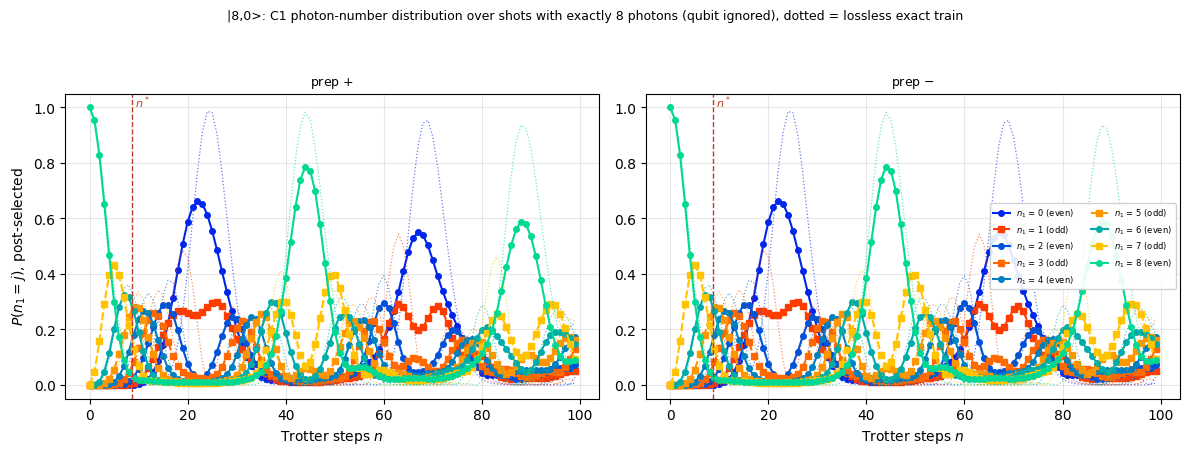

In [33]:
# P(n1 = j) against Trotter step over post-selected shots, one curve per photon number. The
# dashed reference is the lossless answer of CSWAP_TROTTER_SCALING.md section 7: the photons
# split independently and binomially, each transferring with probability sin^2(Theta), so
#     P(n1 = j) = C(N, j) cos^(2j)(Theta) sin^(2(N-j))(Theta),   Theta = n * theta
# BY_QUBIT False ignores the qubit outcome -- transfer out of a Fock state goes as sin^2, which
# is even in the angle the qubit sets, so the unconditional partition is the plain binomial.
# True draws a row per outcome, and those rows are COMPLEMENTARY rather than copies: section 7.5
# locks the qubit to the PARITY of the k = N - n1 transferred photons, so qubit e carries
# n1 = N (mod 2) and qubit g the rest. Weight on the wrong parity is leakage, and it grows with
# the train as loss breaks the correlation.
from math import comb
BY_QUBIT = False

N = postselect_photons
rows = 2 if BY_QUBIT else 1
fig, axs = plt.subplots(rows, len(preps), figsize=(12, 8.2 if BY_QUBIT else 4.6), squeeze=False)
# Even photon numbers get a COOL ramp and odd ones a WARM ramp, brightness rising with j.
# Parity is the physics here -- the qubit outcome is locked to it (section 7.5), so the two
# families never mix -- and it gets the strong visual channel; a single sequential ramp made
# curves of opposite parity look adjacent when they are precisely the ones that never mix.
cool, warm = matplotlib.colormaps["winter"], matplotlib.colormaps["autumn"]
photon_colour = lambda j: (cool if j % 2 == 0 else warm)(0.15 + 0.7 * j / max(levels - 1, 1))
fine = np.linspace(0, max(steps), 300)
for r in range(rows):
    for c, prep in enumerate(preps):
        ax = axs[r][c]
        values = ps_c1_dist[c] if not BY_QUBIT else ps_c1_dist_by_qubit[r][c]
        for j in range(levels):
            colour = photon_colour(j)
            ax.plot(x, values[:, j], "-o" if j % 2 == 0 else "--s", color=colour, markersize=4,
                    label=f"$n_1$ = {j}" + (" (even)" if j % 2 == 0 else " (odd)"))
            ax.plot(train_ref_x, train_ref[:, j], ":", color=colour, lw=0.9, alpha=0.6)
        ax.set_xlabel("Trotter steps $n$")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, alpha=0.3)
        ax.axvline(n_star, color="#c0392b", ls="--", lw=1.0)
        ax.text(n_star, 1.05, " $n^*$", color="#c0392b", fontsize=8, va="top")
        ax.set_title(f"prep ${prep}$" + (f", qubit ${'g' if r == 0 else 'e'}$" if BY_QUBIT
                                         else ""), fontsize=9)
        if c == 0:
            ax.set_ylabel("$P(n_1 = j)$, post-selected")
axs[0][-1].legend(fontsize=6, ncol=2, loc="center right", framealpha=0.9)
fig.suptitle(f"{prep_label}: C1 photon-number distribution over shots with exactly {N} "
             f"photon{'s' if N != 1 else ''}"
             + (" split by qubit outcome" if BY_QUBIT else " (qubit ignored)")
             + ", dotted = lossless exact train", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))


## 5 C1 distribution by qubit


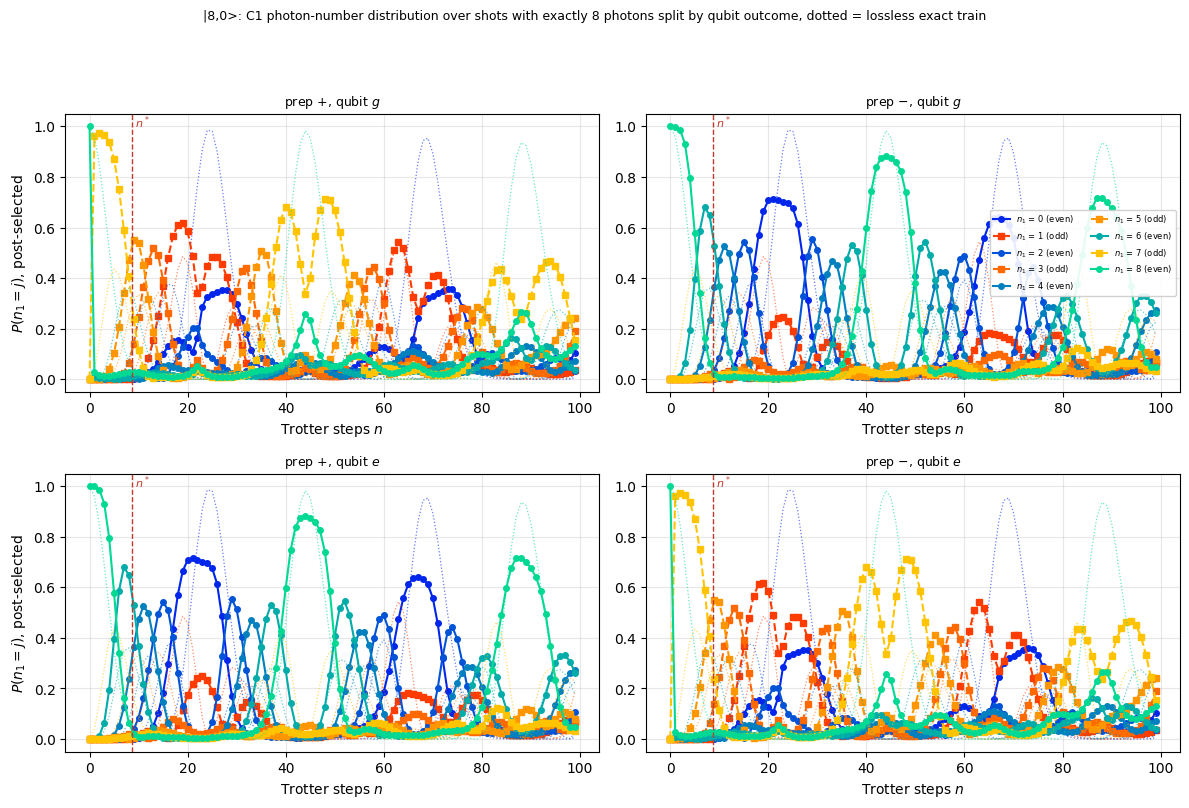

In [34]:
# P(n1 = j) against Trotter step over post-selected shots, one curve per photon number. The
# dashed reference is the lossless answer of CSWAP_TROTTER_SCALING.md section 7: the photons
# split independently and binomially, each transferring with probability sin^2(Theta), so
#     P(n1 = j) = C(N, j) cos^(2j)(Theta) sin^(2(N-j))(Theta),   Theta = n * theta
# BY_QUBIT False ignores the qubit outcome -- transfer out of a Fock state goes as sin^2, which
# is even in the angle the qubit sets, so the unconditional partition is the plain binomial.
# True draws a row per outcome, and those rows are COMPLEMENTARY rather than copies: section 7.5
# locks the qubit to the PARITY of the k = N - n1 transferred photons, so qubit e carries
# n1 = N (mod 2) and qubit g the rest. Weight on the wrong parity is leakage, and it grows with
# the train as loss breaks the correlation.
from math import comb
BY_QUBIT = True

N = postselect_photons
rows = 2 if BY_QUBIT else 1
fig, axs = plt.subplots(rows, len(preps), figsize=(12, 8.2 if BY_QUBIT else 4.6), squeeze=False)
# Even photon numbers get a COOL ramp and odd ones a WARM ramp, brightness rising with j.
# Parity is the physics here -- the qubit outcome is locked to it (section 7.5), so the two
# families never mix -- and it gets the strong visual channel; a single sequential ramp made
# curves of opposite parity look adjacent when they are precisely the ones that never mix.
cool, warm = matplotlib.colormaps["winter"], matplotlib.colormaps["autumn"]
photon_colour = lambda j: (cool if j % 2 == 0 else warm)(0.15 + 0.7 * j / max(levels - 1, 1))
fine = np.linspace(0, max(steps), 300)
for r in range(rows):
    for c, prep in enumerate(preps):
        ax = axs[r][c]
        values = ps_c1_dist[c] if not BY_QUBIT else ps_c1_dist_by_qubit[r][c]
        for j in range(levels):
            colour = photon_colour(j)
            ax.plot(x, values[:, j], "-o" if j % 2 == 0 else "--s", color=colour, markersize=4,
                    label=f"$n_1$ = {j}" + (" (even)" if j % 2 == 0 else " (odd)"))
            ax.plot(train_ref_x, train_ref[:, j], ":", color=colour, lw=0.9, alpha=0.6)
        ax.set_xlabel("Trotter steps $n$")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, alpha=0.3)
        ax.axvline(n_star, color="#c0392b", ls="--", lw=1.0)
        ax.text(n_star, 1.05, " $n^*$", color="#c0392b", fontsize=8, va="top")
        ax.set_title(f"prep ${prep}$" + (f", qubit ${'g' if r == 0 else 'e'}$" if BY_QUBIT
                                         else ""), fontsize=9)
        if c == 0:
            ax.set_ylabel("$P(n_1 = j)$, post-selected")
axs[0][-1].legend(fontsize=6, ncol=2, loc="center right", framealpha=0.9)
fig.suptitle(f"{prep_label}: C1 photon-number distribution over shots with exactly {N} "
             f"photon{'s' if N != 1 else ''}"
             + (" split by qubit outcome" if BY_QUBIT else " (qubit ignored)")
             + ", dotted = lossless exact train", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))
